# Community Detection by Spectral Modularity Maximisation
## Zachary's Karate Club Network · DSC212 - Graph Theory Research Assignment

| | |
|:--|:--|
| **Author** | Srashti Bhatt |
| **Roll number** | IMS25206 |
| **Email** | srashtibhatt25@iisertvm.ac.in |
| **Repository** | https://github.com/srashtibhatt/DSC212-Modularity-Karate-Club |

---

### Abstract

This notebook develops **Newman's spectral method for community detection entirely from first principles** and applies it to Zachary's Karate Club network, the canonical benchmark of the field. The complete workflow:

1. Assemble the **modularity matrix** $B = A - \frac{\mathbf{k}\mathbf{k}^\top}{2m}$ from the adjacency matrix.
2. Grow communities by **recursive spectral bisection**, guided at each step by the leading eigenvector.
3. Declare a community **indivisible** — and stop recursing into it — when its leading eigenvalue satisfies $\lambda_1^{(C)} \le 0$, or when the leading eigenvector cannot separate the nodes by sign (Section 4 explains why both criteria are needed).
4. **Redraw the graph after every split**, so the partition can be watched as it evolves.
5. After every split, recompute **degree, betweenness and closeness centralities and the clustering coefficient** for every node, and track how they evolve.
6. Identify which nodes remain structurally central and analyse how community structure reshapes each metric.

Every mathematical step follows Newman (2006), *Modularity and community structure in networks*, PNAS 103(23): 8577–8582.

> **Primary citation.**
> Newman, M. E. J. (2006). Modularity and community structure in networks. *Proceedings of the National Academy of Sciences*, 103(23), 8577–8582. https://doi.org/10.1073/pnas.0601602103

> **Reproducibility.** `Kernel → Restart & Run All` — the notebook needs no manual edits. All figures are also exported to the `figures/` folder.


## 1 · Environment Setup

The study uses three standard scientific-Python libraries and nothing else: `numpy` (linear algebra, including the symmetric eigensolver `numpy.linalg.eigh`), `networkx` (graph data structures and the metric implementations) and `matplotlib` (every visualisation). No community-detection routine from any library is invoked at any point.


In [1]:
import os
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

FIG_DIR = 'figures'
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({
    'figure.figsize': (10, 7),
    'font.size': 11,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'figure.dpi': 110,
    'savefig.dpi': 150,
    'savefig.bbox': 'tight'
})

print("Libraries loaded successfully.")
print(f"NetworkX version: {nx.__version__}")
print(f"NumPy version:    {np.__version__}")

Libraries loaded successfully.
NetworkX version: 3.6.1
NumPy version:    2.1.3


## 2 · The Dataset - Zachary's Karate Club

The network observed by Wayne Zachary in the early 1970s records the friendships among the **34 members** of a university karate club, connected by **78 ties**. While the study was under way, a dispute between the club's instructor — "Mr. Hi" (node 0) — and its administrator — "Officer" (node 33) — deepened until the club split in two. Because the tie data were collected *before* the rupture, the graph comes with a reliable ground-truth answer, which is why it has remained the standard first benchmark for community-detection methods ever since.


In [2]:
G = nx.karate_club_graph()

# plain unweighted copy (newer NetworkX versions attach a 'weight' attribute to the edges)
G_unweighted = nx.Graph()
G_unweighted.add_nodes_from(G.nodes(data=True))
G_unweighted.add_edges_from(G.edges())

print(f"Nodes: {G_unweighted.number_of_nodes()}")
print(f"Edges: {G_unweighted.number_of_edges()}")
print(f"Is connected: {nx.is_connected(G_unweighted)}")

gt = nx.get_node_attributes(G, 'club')
mr_hi   = sorted([n for n, c in gt.items() if c == 'Mr. Hi'])
officer = sorted([n for n, c in gt.items() if c == 'Officer'])
print(f"\nGround truth - Mr. Hi faction ({len(mr_hi)} members): {mr_hi}")
print(f"Ground truth - Officer faction ({len(officer)} members): {officer}")

Nodes: 34
Edges: 78
Is connected: True

Ground truth - Mr. Hi faction (17 members): [0, 1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12, 13, 16, 17, 19, 21]
Ground truth - Officer faction (17 members): [9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]


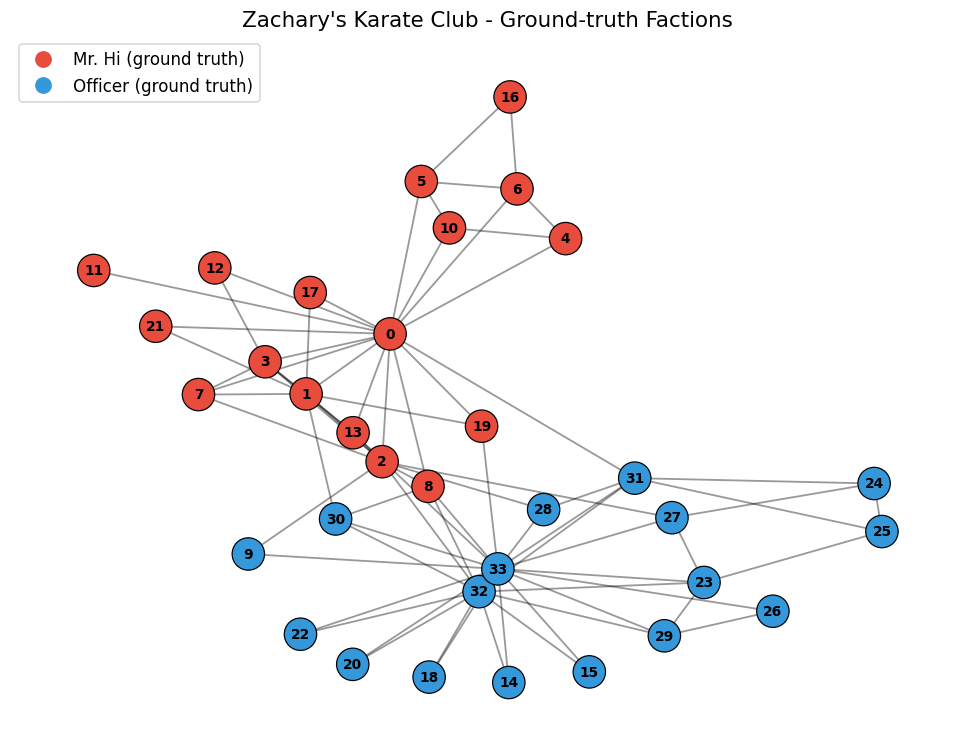

In [3]:
# One fixed layout, reused for EVERY figure in this notebook
pos = nx.spring_layout(G_unweighted, seed=42, k=0.6, iterations=100)

fig, ax = plt.subplots(figsize=(9, 7))
colors_gt = ['#e74c3c' if gt[n] == 'Mr. Hi' else '#3498db' for n in G_unweighted.nodes()]
nx.draw_networkx_nodes(G_unweighted, pos, node_color=colors_gt, node_size=450, ax=ax, edgecolors='black', linewidths=0.8)
nx.draw_networkx_edges(G_unweighted, pos, alpha=0.4, width=1.2, ax=ax)
nx.draw_networkx_labels(G_unweighted, pos, font_size=9, font_weight='bold', ax=ax)
legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#e74c3c', markersize=12, label='Mr. Hi (ground truth)'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#3498db', markersize=12, label='Officer (ground truth)')
]
ax.legend(handles=legend_elements, loc='upper left', frameon=True)
ax.set_title("Zachary's Karate Club - Ground-truth Factions")
ax.axis('off')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/01_ground_truth.png')
plt.show()

## 3 · Mathematical Background — the Modularity Matrix

Throughout, $G=(V,E)$ is an undirected graph with $n=|V|$ vertices and $m=|E|$ edges, adjacency matrix $A$ and degree vector $\mathbf{k}$.

| Symbol | Meaning |
|:--|:--|
| $A$ | adjacency matrix of the graph |
| $\mathbf{k}$ | degree vector ($k_i=\sum_j A_{ij}$) |
| $s\in\{-1,+1\}^n$ | label vector encoding a bipartition |
| $B^{(C)}$ | modularity matrix restricted to a community $C$ |

The method rests on the **modularity matrix**

$$
B = A - \frac{\mathbf{k}\mathbf{k}^\top}{2m}.
$$

Its entry $B_{ij}$ compares the observed adjacency $A_{ij}$ with the number of edges expected between $i$ and $j$ by chance, $k_ik_j/2m$, under a configuration-model null that preserves every degree. Entries above zero mark pairs that are tied more often than chance predicts.

Encoding a bipartition by a label vector $s\in\{-1,+1\}^n$, its modularity is the quadratic form

$$
Q = \frac{1}{4m}\, s^\top B s.
$$

Maximising this expression over continuous unit vectors $\|s\|_2=1$ is a Rayleigh-quotient problem, and the Rayleigh–Ritz theorem identifies the maximiser as the **leading eigenvector** $u_1$ of $B$; a discrete bipartition is then read off from the sign pattern of its entries.

For a community $C\subseteq V$ that has already been isolated, the splitting criterion works on the *restricted* matrix $B^{(C)}$, formed by selecting the rows and columns of the **global** $B$ that correspond to the members of $C$. The null model itself stays global, exactly as prescribed in the assignment handout.

**Sign convention.** An eigenvector is defined only up to a factor of $\pm1$, so every eigenvector is normalised such that its largest-magnitude entry is positive — this removes the last source of ambiguity and makes the notebook reproducible on any machine. The helper functions below construct $B$, extract the leading eigenpair, and evaluate the multi-community modularity.


In [4]:
def modularity_matrix(G, nodelist=None):
    '''Construct the modularity matrix B = A - kk^T/(2m) for an undirected graph.'''
    if nodelist is None:
        nodelist = sorted(G.nodes())
    A = nx.to_numpy_array(G, nodelist=nodelist, weight=None)
    k = A.sum(axis=1)
    m = A.sum() / 2.0
    if m == 0:
        return np.zeros_like(A), nodelist, 0.0
    B = A - np.outer(k, k) / (2.0 * m)
    B = (B + B.T) / 2.0
    return B, nodelist, m


def leading_eigenpair(M):
    '''Largest eigenvalue of a real symmetric matrix and its unit eigenvector (sign-fixed).'''
    evals, evecs = np.linalg.eigh(M)          # eigenvalues in ascending order
    lam, u = evals[-1], evecs[:, -1].copy()
    u *= np.sign(u[np.argmax(np.abs(u))])     # eigenvectors are only defined up to +-1
    return lam, u


def modularity_of_partition(B, m, nodes, partition):
    '''Q = (1/2m) * sum_ij B_ij * delta(c_i, c_j)   (multi-community version of Q = s^T B s / 4m).'''
    idx = {v: i for i, v in enumerate(nodes)}
    label = np.empty(len(nodes), dtype=int)
    for c, comm in enumerate(partition):
        for v in comm:
            label[idx[v]] = c
    same = label[:, None] == label[None, :]
    return float((B * same).sum() / (2.0 * m))


B_full, nodes_full, m_full = modularity_matrix(G_unweighted)
print(f"Full modularity matrix shape: {B_full.shape}")
print(f"Number of edges m = {m_full:.0f}")
print(f"B symmetric (Proposition 1):          {np.allclose(B_full, B_full.T)}")
print(f"||B 1|| (Proposition 2, should be ~0): {np.linalg.norm(B_full @ np.ones(len(nodes_full))):.2e}")

lam1, u1 = leading_eigenpair(B_full)
print(f"Leading eigenvalue lambda_1 = {lam1:.6f}")
print(f"Leading eigenvector (first 10 entries): {np.round(u1[:10], 4)}")

Full modularity matrix shape: (34, 34)
Number of edges m = 78
B symmetric (Proposition 1):          True
||B 1|| (Proposition 2, should be ~0): 1.70e-15
Leading eigenvalue lambda_1 = 4.977080
Leading eigenvector (first 10 entries): [ 0.3875  0.2696  0.1319  0.2535  0.134   0.1457  0.1457  0.2094 -0.0545
 -0.0479]


## 4 · Splitting a Single Community

For a candidate community $C$ the bisection proceeds through four steps:

1. Extract the restricted modularity matrix $B^{(C)}$ from the global matrix.
2. Compute its leading eigenpair $(\lambda_1^{(C)}, u_1^{(C)})$.
3. If $\lambda_1^{(C)} \le 0$, no division of $C$ can increase modularity: declare $C$ indivisible.
4. Otherwise split by sign: node $i$ joins the $+$ side if $(u_1)_i>0$, and the $-$ side otherwise.

> **A practical subtlety, worth emphasising.** For the plain block $B^{(C)}$ of a *cohesive* community, Rayleigh–Ritz guarantees $\lambda_1^{(C)} \ge \mathbf 1^\top B^{(C)}\mathbf 1/|C|$, and $\mathbf 1^\top B^{(C)}\mathbf 1>0$ whenever $C$ holds more internal edges than chance would place there. Every community more cohesive than random therefore has $\lambda_1^{(C)}>0$ automatically — and in exactly that regime the leading eigenvector tends to carry a single sign, leaving the sign rule with nothing to separate. This is precisely what happens in the runs below. The implementation consequently treats **a leading eigenvector whose entries all share one sign** as a second, independent stopping condition, and always states explicitly which criterion ended the recursion. Section 11 revisits the issue with Newman's generalised matrix $B^{(g)}$, for which "$\lambda_1\le 0$" is a genuinely valid stopping test.


In [5]:
def spectral_bipartition(community, global_B, global_nodes, generalized=False, tol=1e-10):
    '''Try to bipartition `community` with the leading eigenvector of its restricted modularity matrix.

    Returns (status, C_plus, C_minus, lambda1) where status is one of
      'split'                   - a genuine bipartition was found
      'nonpositive_eigenvalue'  - lambda_1 <= 0  (handout stopping rule)
      'one_signed_eigenvector'  - lambda_1 > 0 but u_1 has a single sign, so the sign rule cannot split
      'too_small'               - fewer than 2 nodes
    '''
    community = sorted(community)
    if len(community) < 2:
        return 'too_small', [], [], 0.0

    node_to_idx = {n: i for i, n in enumerate(global_nodes)}
    idx = [node_to_idx[n] for n in community]
    B_C = global_B[np.ix_(idx, idx)]
    if generalized:                                   # Newman's B^(g): subtract diag(row sums)  (used in Section 11 only)
        B_C = B_C - np.diag(B_C.sum(axis=1))

    lam1, u1 = leading_eigenpair(B_C)

    if lam1 <= tol:
        return 'nonpositive_eigenvalue', [], [], float(lam1)

    C_plus  = [v for v, x in zip(community, u1) if x > 0]
    C_minus = [v for v, x in zip(community, u1) if x <= 0]
    if len(C_plus) == 0 or len(C_minus) == 0:
        return 'one_signed_eigenvector', [], [], float(lam1)

    return 'split', C_plus, C_minus, float(lam1)

## 5 · Recursive Partitioning of the Whole Graph

The global algorithm is Newman's classic divide-and-conquer scheme:

1. Start from the full vertex set $V$.
2. Pop a community from the work list and attempt the spectral bisection of Section 4; if it splits, push both halves back onto the list.
3. Every intermediate partition is stored in a `history` list, which later drives the step-by-step visualisation and the per-split computation of the node metrics.

**Colour bookkeeping.** To keep the figures comparable, one child of every split **inherits the parent's colour** while the other receives a **fresh** colour — so any colour change between consecutive panels identifies exactly the nodes that the latest split detached.


In [6]:
def recursive_spectral_modularity(G, generalized=False, verbose=True, max_splits=50):
    '''Recursive spectral bisection. Returns history, final_communities, B, nodes, m.'''
    B, nodes, m = modularity_matrix(G)

    active = [sorted(nodes)]
    final = []
    colour_of = {v: 0 for v in nodes}      # node -> colour id (stable across iterations)
    next_colour = 1
    iteration = 0

    history = [{
        'iteration': 0,
        'partition': [sorted(nodes)],
        'colours': dict(colour_of),
        'split': None,
        'lambda': None,
        'n_communities': 1
    }]

    while active and iteration < max_splits:
        C = active.pop(0)
        status, Cp, Cm, lam = spectral_bipartition(C, B, nodes, generalized=generalized)

        if status == 'split':
            iteration += 1
            for v in Cm:                                  # Cp keeps the parent's colour, Cm gets a new one
                colour_of[v] = next_colour
            next_colour += 1

            partition = final + active + [sorted(Cp), sorted(Cm)]
            history.append({
                'iteration': iteration,
                'partition': [list(c) for c in partition],
                'colours': dict(colour_of),
                'split': (list(C), list(Cp), list(Cm)),
                'lambda': lam,
                'n_communities': len(partition)
            })
            active.append(sorted(Cp))
            active.append(sorted(Cm))
            if verbose:
                print(f"Iteration {iteration}: split community of size {len(C)} "
                      f"(lambda_1 = {lam:.4f}) -> {len(Cp)} + {len(Cm)}")
        else:
            final.append(C)
            if verbose:
                reason = {'nonpositive_eigenvalue': f"lambda_1 = {lam:.2e} <= 0",
                          'one_signed_eigenvector': f"lambda_1 = {lam:.4f} > 0 but leading eigenvector has a single sign",
                          'too_small': "single node"}[status]
                print(f"    community of size {len(C):2d} is indivisible ({reason})")

    final.extend(active)
    return history, [sorted(c) for c in final], B, nodes, m


print("=" * 78)
print("Running recursive spectral modularity partitioning")
print("=" * 78)
history, final_comms, B_global, nodes_global, m = recursive_spectral_modularity(G_unweighted)
print("\n" + "=" * 78)
print(f"Finished after {history[-1]['iteration']} successful splits.")
print(f"Final number of communities: {len(final_comms)}")
for i, c in enumerate(sorted(final_comms, key=lambda x: -len(x)), 1):
    print(f"  Community {i} (size {len(c):2d}): {c}")

Running recursive spectral modularity partitioning
Iteration 1: split community of size 34 (lambda_1 = 4.9771) -> 16 + 18
Iteration 2: split community of size 16 (lambda_1 = 2.9441) -> 10 + 6
Iteration 3: split community of size 18 (lambda_1 = 2.5041) -> 13 + 5
    community of size 10 is indivisible (lambda_1 = 2.5712 > 0 but leading eigenvector has a single sign)
Iteration 4: split community of size 6 (lambda_1 = 2.1480) -> 5 + 1
    community of size 13 is indivisible (lambda_1 = 2.3563 > 0 but leading eigenvector has a single sign)
    community of size  5 is indivisible (lambda_1 = 1.8759 > 0 but leading eigenvector has a single sign)
    community of size  5 is indivisible (lambda_1 = 2.1470 > 0 but leading eigenvector has a single sign)
    community of size  1 is indivisible (single node)

Finished after 4 successful splits.
Final number of communities: 5
  Community 1 (size 13): [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]
  Community 2 (size 10): [0, 1, 2, 3, 7, 12, 13,

## 6 · Watching the Partition Evolve

Every panel below redraws the same graph on the same pre-computed spring layout; only the node colours change as the communities divide. Labels keep the original node IDs throughout, and colours pass from parent to child, so comparing two consecutive panels pinpoints precisely which nodes the most recent split separated.


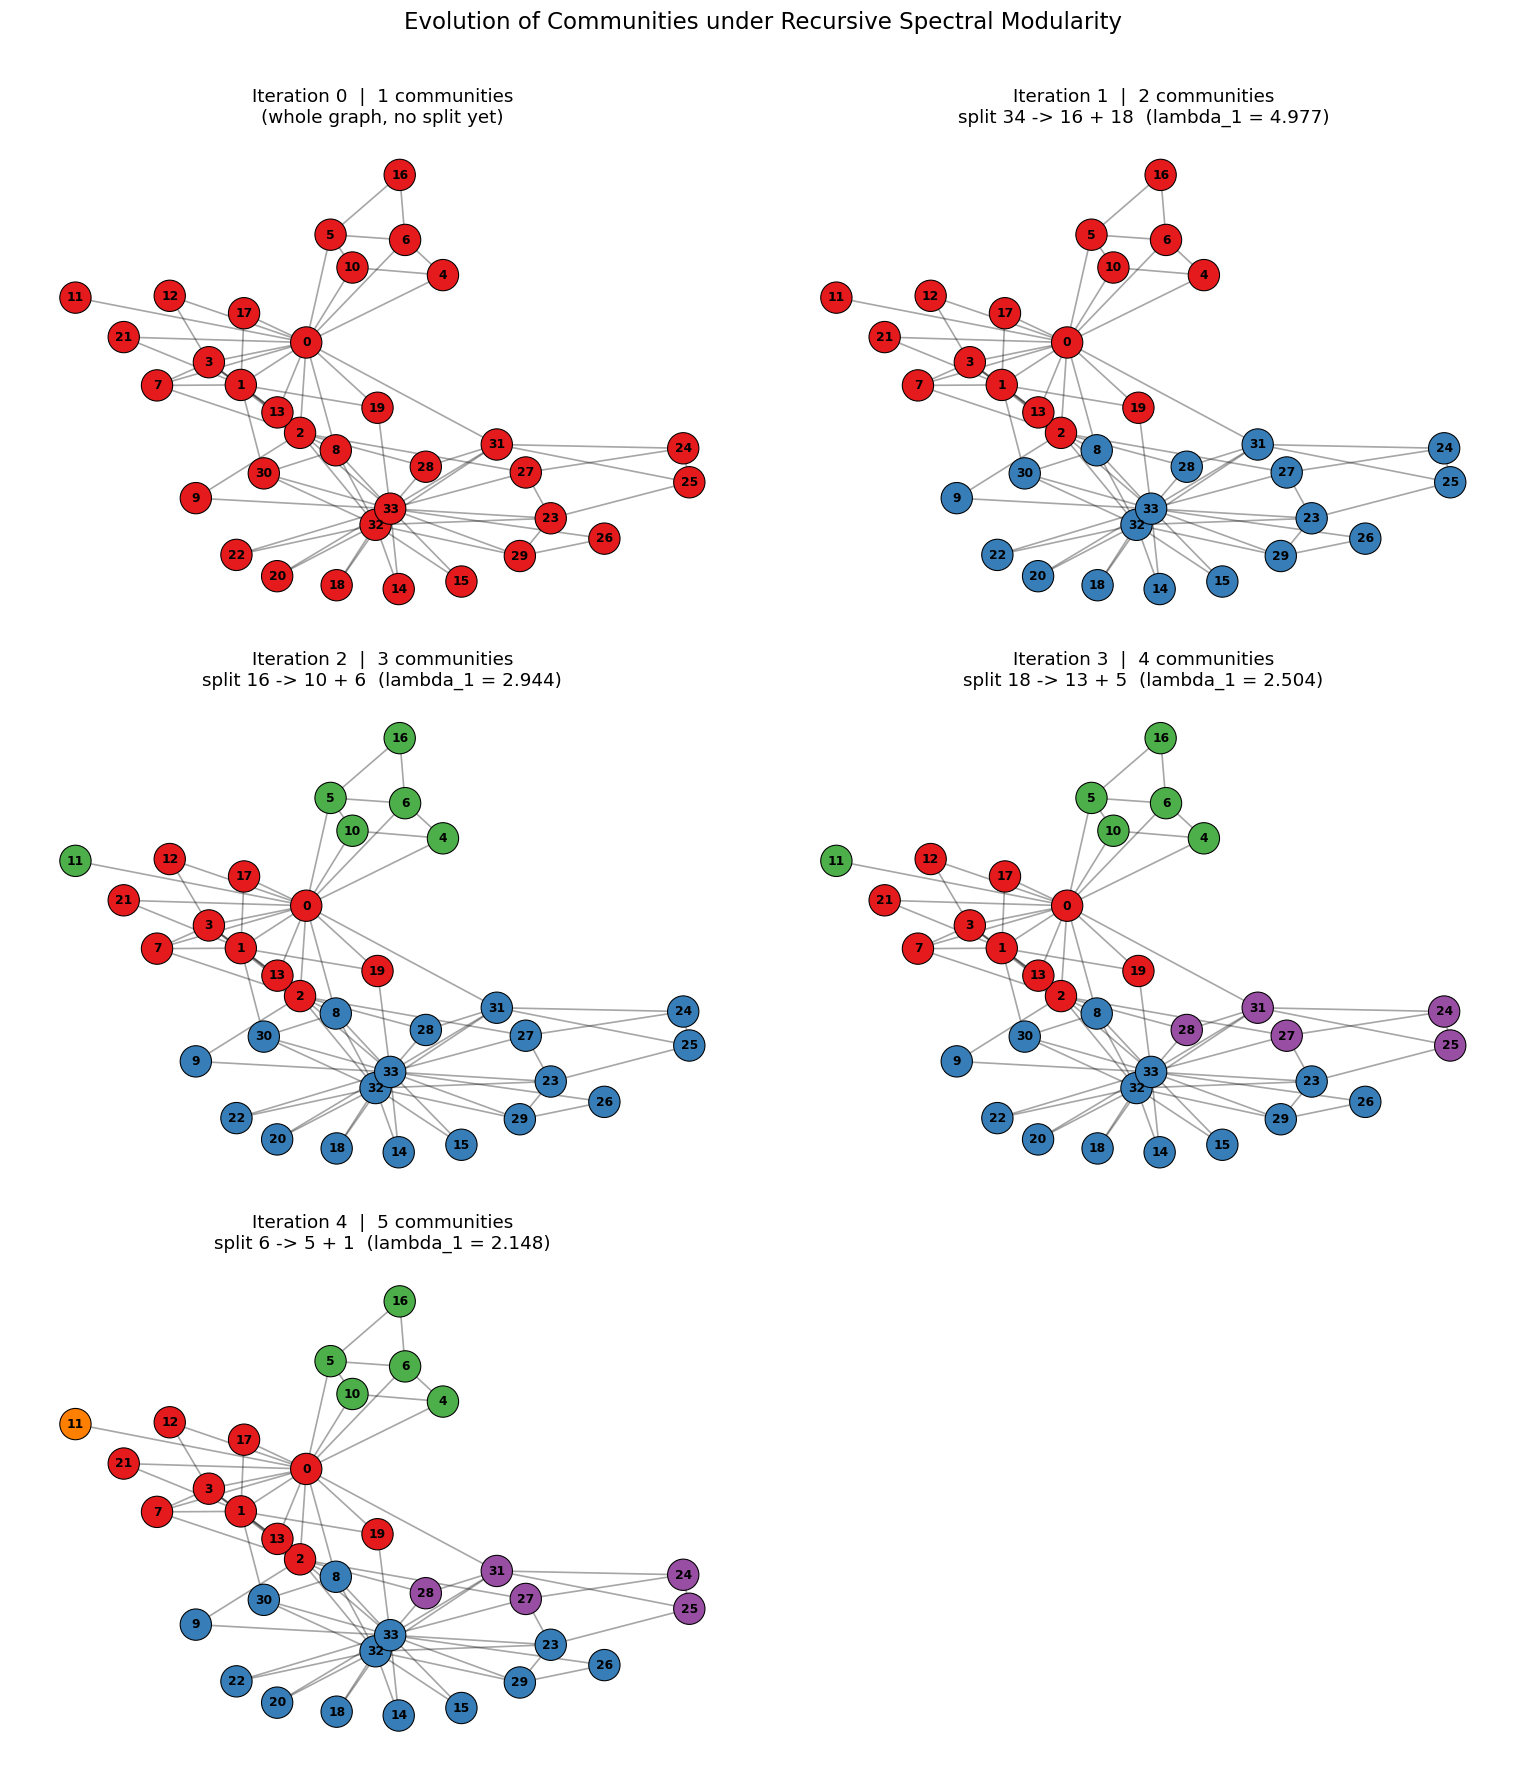

In [7]:
COMMUNITY_COLORS = [
    '#e41a1c', '#377eb8', '#4daf4a', '#984ea3',
    '#ff7f00', '#a65628', '#f781bf', '#999999',
    '#66c2a5', '#fc8d62', '#8da0cb', '#e78ac3'
]

def draw_partition(G, colour_ids, pos, title, ax=None):
    '''Draw the graph with nodes coloured by community (colour_ids: node -> colour id).'''
    if ax is None:
        fig, ax = plt.subplots(figsize=(9, 7))
    colors = [COMMUNITY_COLORS[colour_ids[n] % len(COMMUNITY_COLORS)] for n in G.nodes()]
    nx.draw_networkx_nodes(G, pos, node_color=colors, node_size=420,
                           edgecolors='black', linewidths=0.7, ax=ax)
    nx.draw_networkx_edges(G, pos, alpha=0.35, width=1.1, ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=8, font_weight='bold', ax=ax)
    ax.set_title(title, fontsize=12)
    ax.axis('off')
    return ax


n_stages = len(history)
n_cols = 2
n_rows = (n_stages + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 5.3 * n_rows))
axes = np.array(axes).flatten()

for idx, stage in enumerate(history):
    title = f"Iteration {stage['iteration']}  |  {stage['n_communities']} communities"
    if stage['split'] is not None:
        parent, Cp, Cm = stage['split']
        title += f"\nsplit {len(parent)} -> {len(Cp)} + {len(Cm)}  (lambda_1 = {stage['lambda']:.3f})"
    else:
        title += "\n(whole graph, no split yet)"
    draw_partition(G_unweighted, stage['colours'], pos, title, ax=axes[idx])

for j in range(idx + 1, len(axes)):
    axes[j].axis('off')

plt.suptitle("Evolution of Communities under Recursive Spectral Modularity", fontsize=15, y=1.01)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/02_partition_evolution.png')
plt.show()

## 7 · Node-Level Metrics after Every Split

Alongside the partitioning, four standard NetworkX metrics are recorded for **every node** after every split — iteration 0 being the still-intact graph:

| Metric | Definition | NetworkX call |
|:--|:--|:--|
| Degree centrality | $C_D(i) = k_i/(n-1)$ | `nx.degree_centrality` |
| Betweenness centrality | $C_B(i) = \sum_{s\neq i\neq t}\sigma_{st}(i)/\sigma_{st}$ | `nx.betweenness_centrality` |
| Closeness centrality | $C_C(i) = (n-1)/\sum_{j\neq i}d(i,j)$ | `nx.closeness_centrality` |
| Clustering coefficient | $C(i) = 2T(i)/[k_i(k_i-1)]$ | `nx.clustering` |

**Why the metrics are evaluated inside communities.** Computed on the unchanged full graph, the four metrics would never move, and there would be no evolution to observe. The notebook therefore treats every current community $C$ as a network in its own right: after each split, the metrics are evaluated on the induced subgraph $G[C]$, so each node is scored **relative to the community it currently belongs to**. A value thus measures *how central the node is within its own community*, and it responds whenever a split removes the inter-community edges and shrinks the community. Iteration 0 is the special case in which the single community coincides with the whole graph, so its values are the ordinary global ones.

*Conventions.* A node left alone in its community has no neighbours, so all four of its metrics are recorded as 0 (NetworkX would otherwise report 1.0 as the degree centrality of a one-node graph). Sign-based splitting can leave a community disconnected; in that case `nx.closeness_centrality` applies its default Wasserman–Faust correction, which scales by the fraction of nodes that are reachable.


In [8]:
METRIC_FUNCS = {
    'degree':      nx.degree_centrality,
    'betweenness': nx.betweenness_centrality,
    'closeness':   nx.closeness_centrality,
    'clustering':  nx.clustering,
}

def metrics_for_partition(G, partition):
    '''Metrics of every node, each evaluated inside its own community G[C].'''
    out = {name: {} for name in METRIC_FUNCS}
    for comm in partition:
        if len(comm) == 1:
            for name in METRIC_FUNCS:
                out[name][comm[0]] = 0.0
            continue
        H = G.subgraph(comm)
        for name, f in METRIC_FUNCS.items():
            out[name].update(f(H))
    return out


# metric_history[metric][iteration][node] -> value
metric_history = {name: {} for name in METRIC_FUNCS}
for stage in history:
    vals = metrics_for_partition(G_unweighted, stage['partition'])
    for name in METRIC_FUNCS:
        metric_history[name][stage['iteration']] = vals[name]

iterations = sorted(metric_history['degree'].keys())
print("Metrics recorded for iterations:", iterations)

# sanity check: iteration 0 must coincide with NetworkX on the whole graph
for name, f in METRIC_FUNCS.items():
    whole = f(G_unweighted)
    assert all(abs(whole[v] - metric_history[name][0][v]) < 1e-12 for v in G_unweighted.nodes())
print("Check passed: iteration 0 == metrics on the whole graph.")

global_deg, global_bet = metric_history['degree'][0], metric_history['betweenness'][0]
print("\nTop-5 nodes by (global) degree centrality:")
for v, x in sorted(global_deg.items(), key=lambda t: -t[1])[:5]:
    print(f"  Node {v:2d}: {x:.4f}")
print("\nTop-5 nodes by (global) betweenness centrality:")
for v, x in sorted(global_bet.items(), key=lambda t: -t[1])[:5]:
    print(f"  Node {v:2d}: {x:.4f}")

Metrics recorded for iterations: [0, 1, 2, 3, 4]
Check passed: iteration 0 == metrics on the whole graph.

Top-5 nodes by (global) degree centrality:
  Node 33: 0.5152
  Node  0: 0.4848
  Node 32: 0.3636
  Node  2: 0.3030
  Node  1: 0.2727

Top-5 nodes by (global) betweenness centrality:
  Node  0: 0.4376
  Node 33: 0.3041
  Node 32: 0.1452
  Node  2: 0.1437
  Node 31: 0.1383


## 8 · Visualising the Evolution of the Metrics

**(a) Line plots.** Every node is drawn; the eight most prominent members of the original graph — the union of the top-6 by degree and the top-6 by betweenness — are highlighted in colour, while the remaining 26 nodes stay grey.

**(b) Heat-maps.** Rows are nodes, columns are iterations; this layout keeps *all 34 nodes* visible for every metric at every stage.


Highlighted nodes: [0, 1, 2, 3, 8, 31, 32, 33]


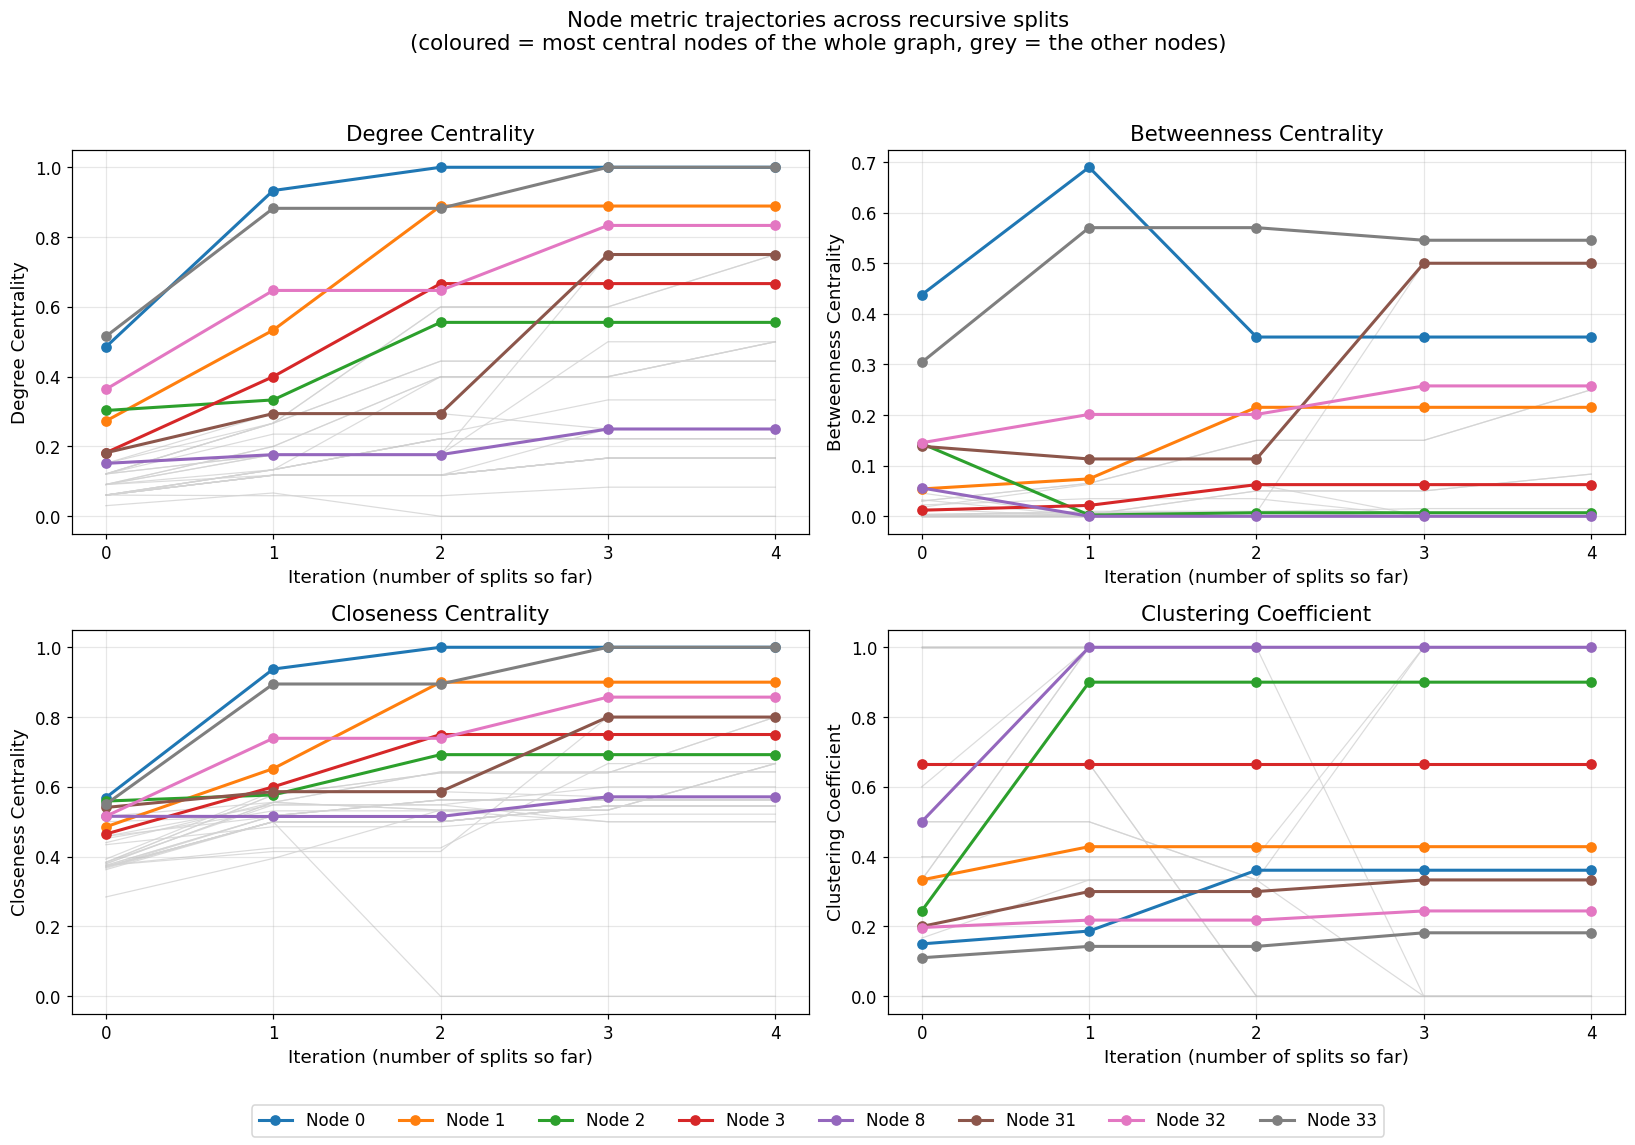

In [9]:
top_degree  = sorted(global_deg, key=global_deg.get, reverse=True)[:6]
top_between = sorted(global_bet, key=global_bet.get, reverse=True)[:6]
highlight_nodes = sorted(set(top_degree + top_between))
print("Highlighted nodes:", highlight_nodes)

metric_names = ['degree', 'betweenness', 'closeness', 'clustering']
titles = ['Degree Centrality', 'Betweenness Centrality', 'Closeness Centrality', 'Clustering Coefficient']
palette = plt.get_cmap('tab10')
hl_colour = {v: palette(i % 10) for i, v in enumerate(highlight_nodes)}

fig, axes = plt.subplots(2, 2, figsize=(15, 10.5))
for ax, metric, title in zip(axes.flat, metric_names, titles):
    for v in G_unweighted.nodes():
        vals = [metric_history[metric][it][v] for it in iterations]
        if v not in highlight_nodes:
            ax.plot(iterations, vals, color='lightgrey', linewidth=0.8, alpha=0.8, zorder=1)
    for v in highlight_nodes:
        vals = [metric_history[metric][it][v] for it in iterations]
        ax.plot(iterations, vals, 'o-', color=hl_colour[v], linewidth=2.0, markersize=6,
                label=f'Node {v}', zorder=3)
    ax.set_xlabel('Iteration (number of splits so far)')
    ax.set_ylabel(title)
    ax.set_title(title)
    ax.set_xticks(iterations)
    ax.grid(True, alpha=0.3)

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=len(highlight_nodes), frameon=True)
plt.suptitle("Node metric trajectories across recursive splits\n(coloured = most central nodes of the whole graph, grey = the other nodes)", fontsize=14)
plt.tight_layout(rect=[0, 0.05, 1, 0.95])
plt.savefig(f'{FIG_DIR}/03_metric_evolution_lines.png')
plt.show()

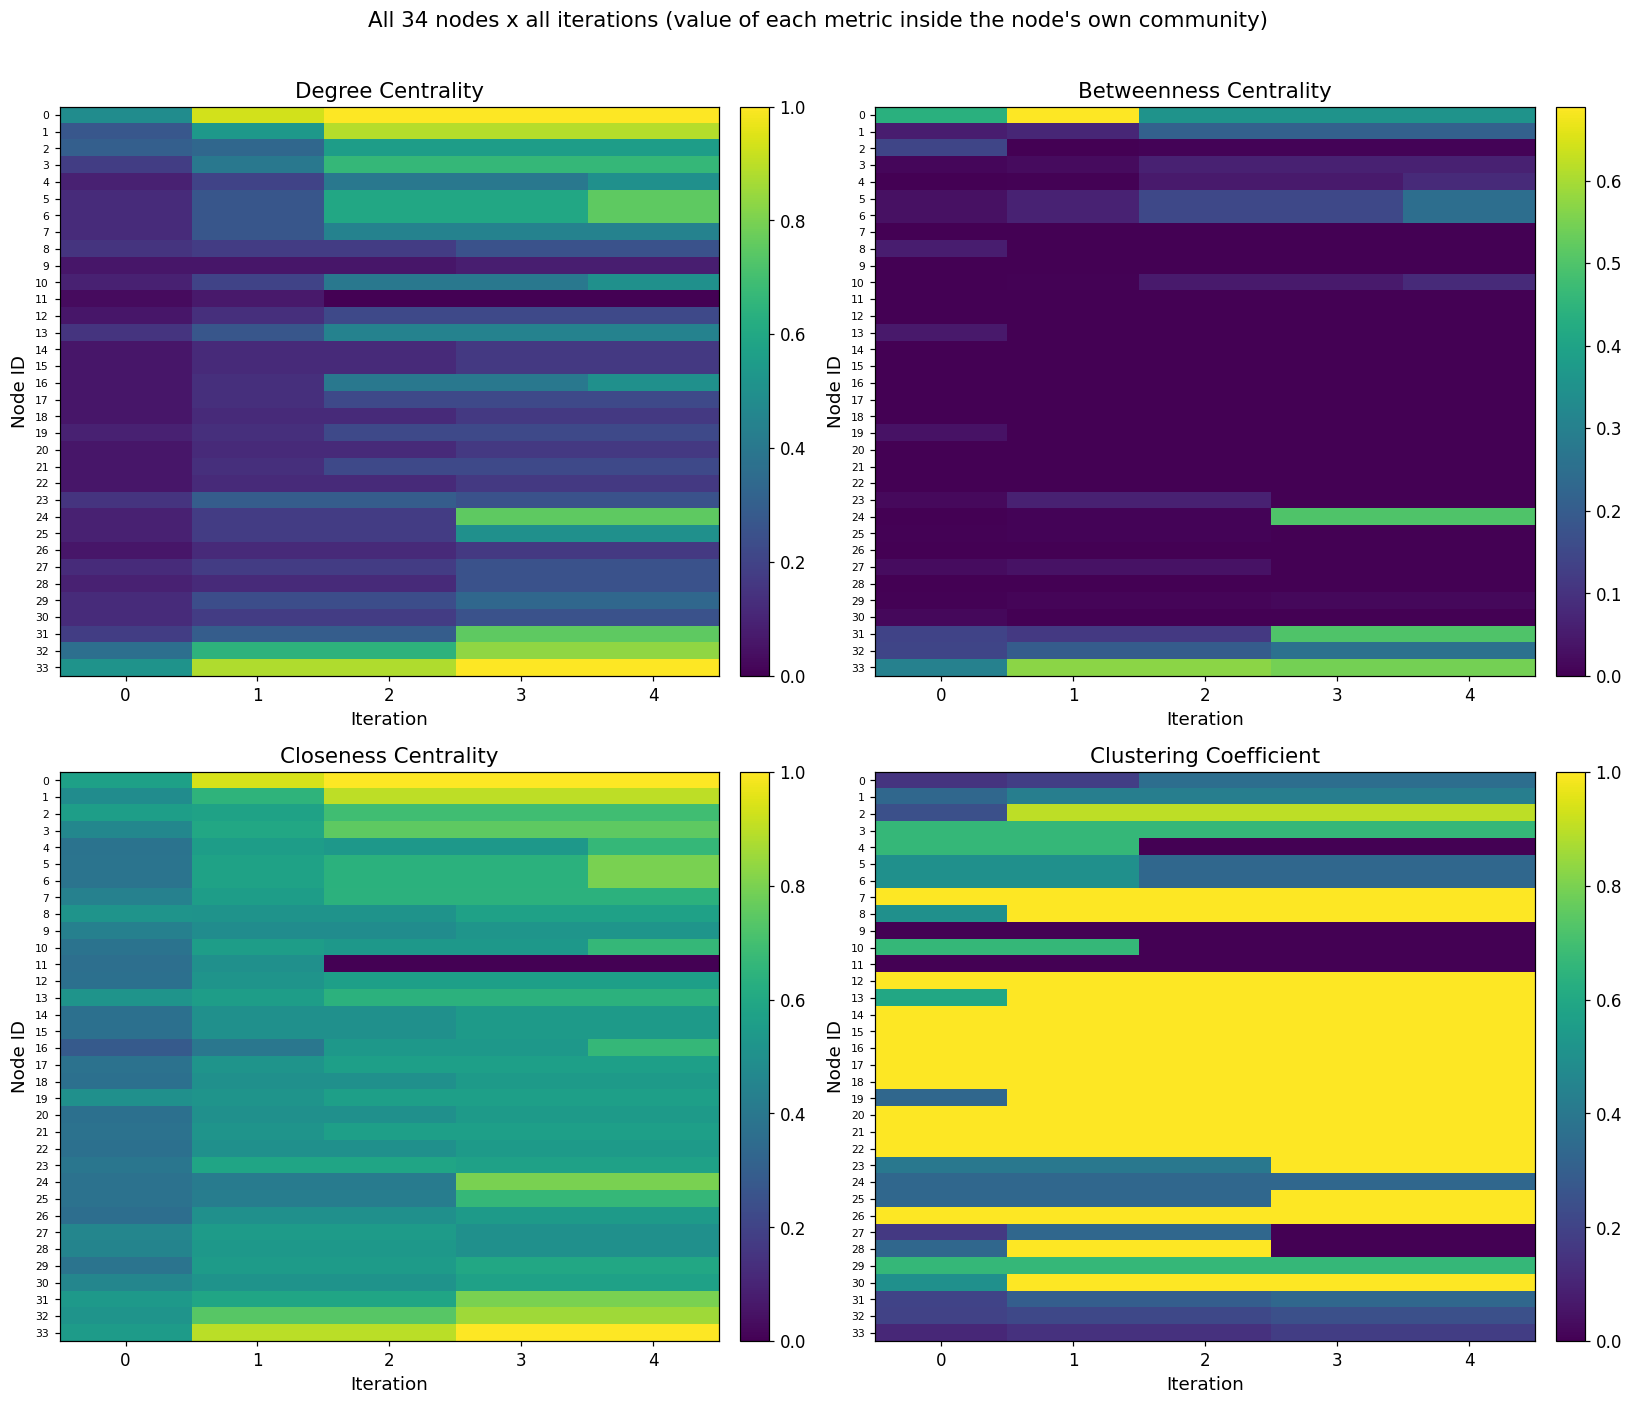

In [10]:
node_order = sorted(G_unweighted.nodes())

fig, axes = plt.subplots(2, 2, figsize=(15, 13))
for ax, metric, title in zip(axes.flat, metric_names, titles):
    M = np.array([[metric_history[metric][it][v] for it in iterations] for v in node_order])
    im = ax.imshow(M, aspect='auto', cmap='viridis', vmin=0, vmax=max(M.max(), 1e-9))
    ax.set_xticks(range(len(iterations)))
    ax.set_xticklabels(iterations)
    ax.set_yticks(range(len(node_order)))
    ax.set_yticklabels(node_order, fontsize=7)
    ax.set_xlabel('Iteration')
    ax.set_ylabel('Node ID')
    ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)

plt.suptitle("All 34 nodes x all iterations (value of each metric inside the node's own community)", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig(f'{FIG_DIR}/04_metric_evolution_heatmaps.png')
plt.show()

## 9 · Final Communities, Modularity Scores and the Ground-Truth Comparison

Every partition is scored with the implementation's own formula, $Q=\frac{1}{2m}\sum_{ij}B_{ij}\delta(c_i,c_j)$, and the value is cross-checked against NetworkX's `nx.community.modularity`. For a two-way split the expressions coincide with $Q=\frac{1}{4m}s^\top B s$ — a direct consequence of $B\mathbf 1=0$.


In [11]:
def nx_modularity(G, communities):
    return nx.community.modularity(G, [set(c) for c in communities], weight=None)

# --- modularity after every iteration ---------------------------------------
print("Modularity after each iteration")
Q_history = []
for stage in history:
    q_own = modularity_of_partition(B_global, m, nodes_global, stage['partition'])
    q_nx  = nx_modularity(G_unweighted, stage['partition'])
    assert abs(q_own - q_nx) < 1e-10
    Q_history.append(q_own)
    print(f"  iteration {stage['iteration']}: {stage['n_communities']} communities, Q = {q_own:.4f}   (NetworkX: {q_nx:.4f})")

Q_final = Q_history[-1]
gt_partition = [mr_hi, officer]
Q_gt = modularity_of_partition(B_global, m, nodes_global, gt_partition)
print(f"\nModularity of the final spectral partition ({len(final_comms)} communities): Q = {Q_final:.4f}")
print(f"Modularity of the historical ground-truth split (2 factions):        Q = {Q_gt:.4f}")

# --- Eq. (1) check for the first bipartition --------------------------------
first_parent, first_plus, first_minus = history[1]['split']
s = np.array([1.0 if v in set(first_plus) else -1.0 for v in nodes_global])
print(f"\nEq.(1) for the first split: s^T B s / (4m) = {s @ B_global @ s / (4 * m):.4f}")

# --- does the FIRST split recover the real fission? -------------------------
side_of_0 = first_plus if 0 in first_plus else first_minus
side_of_33 = first_minus if 0 in first_plus else first_plus
mis = sorted((set(side_of_0) - set(mr_hi)) | (set(side_of_33) - set(officer)))
print("\nFirst spectral bipartition vs. what actually happened:")
print(f"  side containing node 0  ({len(side_of_0)} nodes): {sorted(side_of_0)}")
print(f"  side containing node 33 ({len(side_of_33)} nodes): {sorted(side_of_33)}")
print(f"  misclassified nodes: {mis}  ->  {len(G_unweighted) - len(mis)}/{len(G_unweighted)} correct "
      f"({100 * (len(G_unweighted) - len(mis)) / len(G_unweighted):.1f}%)")

Modularity after each iteration
  iteration 0: 1 communities, Q = -0.0000   (NetworkX: 0.0000)
  iteration 1: 2 communities, Q = 0.3715   (NetworkX: 0.3715)
  iteration 2: 3 communities, Q = 0.3898   (NetworkX: 0.3898)
  iteration 3: 4 communities, Q = 0.4081   (NetworkX: 0.4081)
  iteration 4: 5 communities, Q = 0.4094   (NetworkX: 0.4094)

Modularity of the final spectral partition (5 communities): Q = 0.4094
Modularity of the historical ground-truth split (2 factions):        Q = 0.3582

Eq.(1) for the first split: s^T B s / (4m) = 0.3715

First spectral bipartition vs. what actually happened:
  side containing node 0  (16 nodes): [0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21]
  side containing node 33 (18 nodes): [8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]
  misclassified nodes: [8]  ->  33/34 correct (97.1%)


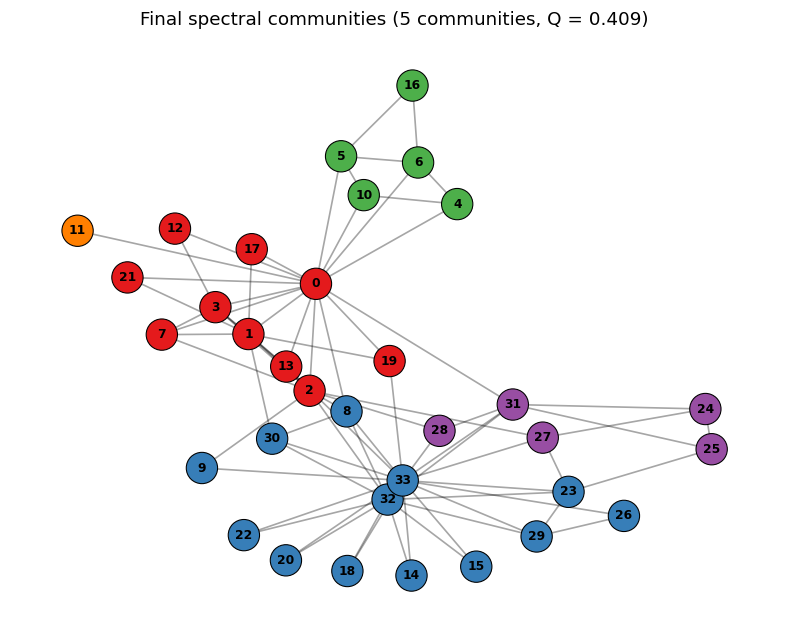

In [12]:
fig, ax = plt.subplots(figsize=(9, 7))
draw_partition(G_unweighted, history[-1]['colours'], pos,
               f"Final spectral communities ({len(final_comms)} communities, Q = {Q_final:.3f})", ax=ax)
plt.savefig(f'{FIG_DIR}/05_final_communities.png')
plt.show()

## 10 · Discussion — Enduring Hubs and the Imprint of Community Structure

The tables quoted throughout this discussion are extracted from the metric history computed above; each claim made below can be traced back to them.


In [13]:
def top_k(d, k=5):
    return sorted(d, key=lambda v: (-d[v], v))[:k]

print("(1) Top-5 nodes of the WHOLE graph (iteration 0)")
for name in metric_names:
    print(f"  {name:12s}", [(v, round(metric_history[name][0][v], 3)) for v in top_k(metric_history[name][0])])

print("\n(2) Most central node INSIDE each community, by betweenness (ties -> lowest ID) - after every iteration")
for stage in history:
    row = []
    for comm in sorted(stage['partition'], key=lambda c: (-len(c), c[0])):
        d = {v: metric_history['betweenness'][stage['iteration']][v] for v in comm}
        leader = top_k(d, 1)[0]
        row.append(f"{leader} (|C|={len(comm)}, B={d[leader]:.2f})")
    print(f"  iter {stage['iteration']}: " + ";  ".join(row))

print("\n(3) Trajectories of selected nodes: values at iterations", iterations)
for name in metric_names:
    print(f"\n  {name}")
    for v in [0, 33, 32, 2, 1, 31, 8, 11]:
        print(f"    node {v:2d}: " + "  ".join(f"{metric_history[name][it][v]:.3f}" for it in iterations))

print("\n(4) Final community of each key node:")
for v in [0, 33, 32, 2, 1, 31, 8, 11]:
    comm = next(c for c in final_comms if v in c)
    print(f"    node {v:2d} -> community of size {len(comm):2d}: {comm}")

(1) Top-5 nodes of the WHOLE graph (iteration 0)
  degree       [(33, 0.515), (0, 0.485), (32, 0.364), (2, 0.303), (1, 0.273)]
  betweenness  [(0, 0.438), (33, 0.304), (32, 0.145), (2, 0.144), (31, 0.138)]
  closeness    [(0, 0.569), (2, 0.559), (33, 0.55), (31, 0.541), (8, 0.516)]
  clustering   [(7, 1.0), (12, 1.0), (14, 1.0), (15, 1.0), (16, 1.0)]

(2) Most central node INSIDE each community, by betweenness (ties -> lowest ID) - after every iteration
  iter 0: 0 (|C|=34, B=0.44)
  iter 1: 33 (|C|=18, B=0.57);  0 (|C|=16, B=0.69)
  iter 2: 33 (|C|=18, B=0.57);  0 (|C|=10, B=0.35);  5 (|C|=6, B=0.15)
  iter 3: 33 (|C|=13, B=0.55);  0 (|C|=10, B=0.35);  5 (|C|=6, B=0.15);  24 (|C|=5, B=0.50)
  iter 4: 33 (|C|=13, B=0.55);  0 (|C|=10, B=0.35);  5 (|C|=5, B=0.25);  24 (|C|=5, B=0.50);  11 (|C|=1, B=0.00)

(3) Trajectories of selected nodes: values at iterations [0, 1, 2, 3, 4]

  degree
    node  0: 0.485  0.933  1.000  1.000  1.000
    node 33: 0.515  0.882  0.882  1.000  1.000
    node

### 10.1 Does the algorithm rediscover the historical split?

Yes — with a single, well-understood exception. The opening bipartition (Section 9) agrees with Zachary's records for **33 of the 34** members; only **node 8** ends up on the wrong side. Three of his five friends (nodes 30, 32, 33) sit with the Officer, two (nodes 0 and 2) with Mr. Hi; reportedly he stayed with Mr. Hi because of an upcoming belt test — a motive that leaves no trace in a friendship graph. The spectral split is in fact *more* modular ($Q=0.3715$) than the real one ($Q=0.3582$): modularity rewards structure in the tie data, not the members' actual allegiance. Recursing further raises $Q$ monotonically to $0.4094$ across **5 communities**: Mr. Hi's side divides into his inner circle $\{0,1,2,3,7,12,13,17,19,21\}$ and the group $\{4,5,6,10,16\}$ hanging off it, while the Officer's side divides into the core around nodes 32/33 and the tight cluster $\{24,25,27,28,31\}$. Node 11, whose only friend is node 0, is left as a singleton.

### 10.2 Which nodes stay central throughout?

Selected trajectories (iteration 0 = intact graph; iteration 4 = value inside the node's final community):

| Node | Affiliation | Degree (iter 0 → 4) | Betweenness (iter 0 → 4) | Closeness (iter 0 → 4) | Clustering (iter 0 → 4) |
|:--|:--|:--|:--|:--|:--|
| **0** | Mr. Hi | 0.485 → 1.000 | 0.438 → 0.354 | 0.569 → 1.000 | 0.150 → 0.361 |
| **33** | Officer | 0.515 → 1.000 | 0.304 → 0.545 | 0.550 → 1.000 | 0.110 → 0.182 |
| **32** | Officer's lieutenant | 0.364 → 0.833 | 0.145 → 0.258 | 0.516 → 0.857 | 0.197 → 0.244 |
| **2** | Mr. Hi side, tied to both factions | 0.303 → 0.556 | 0.144 → 0.007 | 0.559 → 0.692 | 0.244 → 0.900 |
| **1** | Mr. Hi side | 0.273 → 0.889 | 0.054 → 0.215 | 0.485 → 0.900 | 0.333 → 0.429 |
| **31** | Officer side | 0.182 → 0.750 | 0.138 → 0.500 | 0.541 → 0.800 | 0.200 → 0.333 |
| **8** | the misclassified node | 0.152 → 0.250 | 0.056 → 0.000 | 0.516 → 0.571 | 0.500 → 1.000 |
| **11** | pendant on node 0 | 0.030 → 0.000 | 0.000 → 0.000 | 0.367 → 0.000 | 0.000 → 0.000 |

- **Nodes 0 and 33 are the durable hubs.** They rank first and second in the intact graph for both degree and betweenness (node 0 leads in betweenness and closeness, node 33 in degree). After every split each remains the highest-betweenness node inside its own community (output (2) of the cell above), and inside their final communities each is adjacent to *every* other member (degree = closeness = 1.0). The two historical leaders are thus the structural hubs both of the whole club and of the faction that forms around each of them.
- **A second tier of hubs emerges inside the factions.** Node 32 is the clear runner-up on the Officer side (degree 0.364 → 0.833; from the first split onwards it holds the second-highest degree in node 33's community). Node 1 becomes the second hub of Mr. Hi's inner circle (degree 0.889, behind only node 0), and node 31 ties with node 24 at the top of the small community $\{24,25,27,28,31\}$ (degree 0.750; its betweenness climbs from 0.138 to 0.500).
- **Global centrality does not guarantee local centrality.** Node 2 ranks 4th in degree and 2nd in closeness globally, yet its betweenness collapses from 0.144 to 0.002 at the very first split: its brokerage came from friends on the *opposite* faction's side (nodes 8, 9, 27, 28, 32), and those edges are severed the moment the factions separate. Node 8 loses its brokerage in the same way (betweenness 0.056 → 0).

### 10.3 How does community structure reshape each metric?

- **Degree centrality** counts only edges inside the community and divides by $|C|-1$. It rises for almost every node because the denominator shrinks faster than friends are lost, and both leaders reach 1.0. The exceptions are the nodes that lose many friends across the divide: node 23 (0.294 → 0.250 once its neighbours 25 and 27 are split off), node 9 (0.061 → 0.059) and node 11 (0.030 → 0.067 → 0.000, its only friend node 0 ending up in another community).
- **Closeness** behaves like degree: distances contract once the long inter-community paths disappear, so values climb towards 1 for the hubs of small, dense communities. It is also the metric most sensitive to isolation (node 11: 0.367 → 0.500 → 0).
- **Betweenness** is the metric most reshaped by community structure. It concentrates on the nodes that tie sub-groups of the *same* community together (node 0: 0.438 → 0.690 inside the 16-node Mr. Hi side → 0.354 once the periphery $\{4,5,6,10,11,16\}$ splits away), and it evaporates for nodes whose brokerage ran *between* communities (nodes 2 and 8). Global betweenness, in other words, measures who connects communities; within-community betweenness measures who holds a community together.
- **Clustering coefficient** is the one metric on which hubs do *not* lead: globally the top values (1.0) belong to low-degree members such as 7, 12, 14, 15 and 16, whose few friends all know one another, while the two leaders sit low (node 0: 0.150, node 33: 0.110) because they connect people who do not know each other. Deleting the inter-community edges raises the clustering of members who had friends across the divide (node 2: 0.244 → 0.900; node 8: 0.500 → 1.000), since their remaining neighbours now all belong to one tight group.

### 10.4 Caveats and limitations

- After iteration 0 the metrics are evaluated *inside* communities, so values from communities of different sizes are not directly comparable — a node in a 5-node community can reach 1.0 far more easily than one in a 13-node community. The meaningful quantity is the relative ordering within a community.
- Sign-based splitting does not guarantee connected communities: the 6-node community $\{4,5,6,10,11,16\}$ present at iterations 2–3 is disconnected (node 11's only friend, node 0, sits elsewhere) and is subsequently split into $\{4,5,6,10,16\}$ and the singleton $\{11\}$. The generalised matrix $B^{(g)}$ of Section 11 keeps node 11 with node 0 and avoids the singleton altogether.
- Modularity-based refinement cannot "repair" node 8: moving it to Mr. Hi's side *lowers* $Q$ from 0.3715 to 0.3582 (the real split differs from the spectral one only in node 8). It is the case where the friendship structure and the members' actual decisions disagree.
- The method is deterministic and parameter-free; on large graphs the dense `eigh` solver should be replaced by a sparse Lanczos eigensolver.


## 11 · Why the Handout's Stopping Rule Needs a Correction

In Newman (2006), the matrix used to split an established group $g$ is the *generalised* modularity matrix

$$
B^{(g)}_{ij} \;=\; B_{ij} \;-\; \delta_{ij}\sum_{l\in g} B_{il},
$$

that is, the block $B^{(C)}$ with its row sums subtracted from the diagonal. This matrix satisfies $B^{(g)}\mathbf 1=\mathbf 0$ — just like the global $B$ — so $\lambda_1\ge 0$ always holds, and the modularity gain of splitting $g$ with $s\in\{\pm1\}^{|g|}$ is **exactly** $\Delta Q = \frac{1}{4m}s^\top B^{(g)}s$. With the plain block $B^{(C)}$ that identity does **not** hold. The cell below verifies both statements numerically for the two communities created by the first split.


In [14]:
def delta_Q_check(parent, other):
    '''Split `parent` with the leading eigenvector of (a) plain block, (b) Newman's B^(g); compare gains.'''
    idx = parent
    B_C = B_global[np.ix_(idx, idx)]
    B_g = B_C - np.diag(B_C.sum(axis=1))
    Q_before = modularity_of_partition(B_global, m, nodes_global, [parent, other])
    rows = []
    for label, M in [('plain block B^(C)  (handout)', B_C), ("Newman's B^(g)", B_g)]:
        lam, u = leading_eigenpair(M)
        s = np.where(u > 0, 1.0, -1.0)
        c1 = [v for v, x in zip(parent, s) if x > 0]
        c2 = [v for v, x in zip(parent, s) if x < 0]
        dQ_true = modularity_of_partition(B_global, m, nodes_global, [c1, c2, other]) - Q_before
        rows.append((label, len(c1), len(c2), dQ_true, s @ B_C @ s / (4 * m), s @ B_g @ s / (4 * m)))
    return rows

C0, C33 = sorted(side_of_0), sorted(side_of_33)
for name, parent, other in [("community containing node 0", C0, C33), ("community containing node 33", C33, C0)]:
    print(f"Splitting the {name} (size {len(parent)}):")
    print(f"  {'matrix used to find s':32s} {'sizes':>7s} {'true dQ':>9s} {'s^T B^(C) s/4m':>15s} {'s^T B^(g) s/4m':>15s}")
    for label, a, b, dq, f_plain, f_gen in delta_Q_check(parent, other):
        print(f"  {label:32s} {a:>3d}+{b:<3d} {dq:9.4f} {f_plain:15.4f} {f_gen:15.4f}")
    print()

Splitting the community containing node 0 (size 16):
  matrix used to find s              sizes   true dQ  s^T B^(C) s/4m  s^T B^(g) s/4m
  plain block B^(C)  (handout)      10+6      0.0183          0.1112          0.0183
  Newman's B^(g)                     9+7      0.0012          0.0941          0.0012

Splitting the community containing node 33 (size 18):
  matrix used to find s              sizes   true dQ  s^T B^(C) s/4m  s^T B^(g) s/4m
  plain block B^(C)  (handout)      13+5      0.0183          0.1112          0.0183
  Newman's B^(g)                     6+12     0.0207          0.1136          0.0207



In [15]:
print("Recursive bisection with Newman's generalised matrix B^(g):\n")
hist_g, final_g, *_ = recursive_spectral_modularity(G_unweighted, generalized=True, verbose=True)
Q_g = modularity_of_partition(B_global, m, nodes_global, final_g)
print(f"\nFinal: {len(final_g)} communities, Q = {Q_g:.4f}")
for c in sorted(final_g, key=lambda c: (-len(c), c[0])):
    print(f"  size {len(c):2d}: {c}")
print(f"\nCompare: handout-style block B^(C): {len(final_comms)} communities, Q = {Q_final:.4f}  (contains the singleton {[c for c in final_comms if len(c)==1]})")

Recursive bisection with Newman's generalised matrix B^(g):

Iteration 1: split community of size 34 (lambda_1 = 4.9771) -> 16 + 18
Iteration 2: split community of size 16 (lambda_1 = 1.1785) -> 9 + 7
Iteration 3: split community of size 18 (lambda_1 = 0.8594) -> 6 + 12
Iteration 4: split community of size 9 (lambda_1 = 0.0602) -> 4 + 5
    community of size  7 is indivisible (lambda_1 = -4.02e-16 <= 0)
    community of size  6 is indivisible (lambda_1 = 4.48e-16 <= 0)
    community of size 12 is indivisible (lambda_1 = -1.19e-16 <= 0)
    community of size  4 is indivisible (lambda_1 = 2.40e-17 <= 0)
    community of size  5 is indivisible (lambda_1 = -2.39e-16 <= 0)

Final: 5 communities, Q = 0.3776
  size 12: [8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33]
  size  7: [0, 4, 5, 6, 10, 11, 16]
  size  6: [23, 24, 25, 27, 28, 31]
  size  5: [2, 3, 7, 12, 13]
  size  4: [1, 17, 19, 21]

Compare: handout-style block B^(C): 5 communities, Q = 0.4094  (contains the singleton [[11]])


**Take-away.** With $B^{(g)}$ the rule "stop when $\lambda_1\le 0$" is sound: it certifies $\Delta Q\le 0$ for every conceivable split, the one-signed-eigenvector guard becomes unnecessary, and no singleton such as node 11 is ever split off. The two variants agree on the first — and most consequential — split and differ only in how the two large factions are subdivided further. Note also that the handout-style plain block happens to reach the *higher* final $Q$ in this run (see the last line of the output above): the plain block carries no gain guarantee, yet every accepted split did increase $Q$ here (Section 9). As required, the main body of this notebook follows the handout and its plain block $B^{(C)}$.


## References

1. Newman, M. E. J. (2006). Modularity and community structure in networks. *Proceedings of the National Academy of Sciences*, **103**(23), 8577–8582. https://doi.org/10.1073/pnas.0601602103

2. Zachary, W. W. (1977). An information flow model for conflict and fission in small groups. *Journal of Anthropological Research*, **33**(4), 452–473.

3. NetworkX developers. *NetworkX documentation — community detection algorithms*. https://networkx.org/documentation/stable/reference/algorithms/community.html
